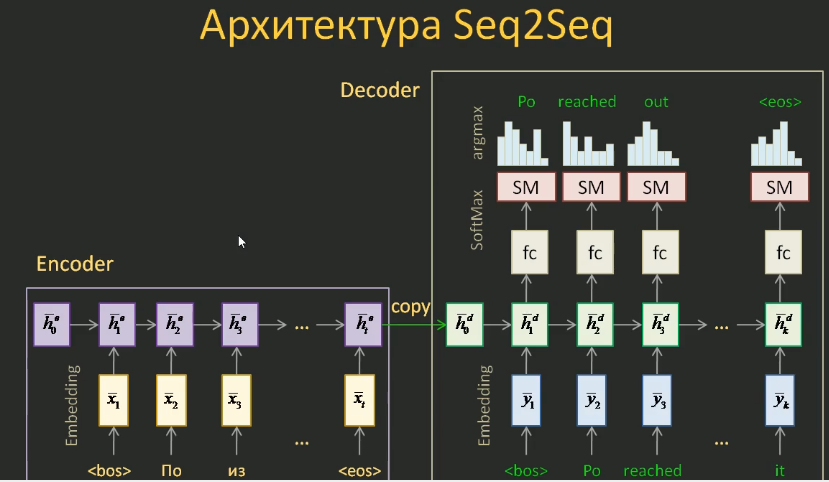

В архитектуре seq2seq скрытое состояние енкодера всего одно (последнее), а оно постепенно теряет информацию о словах, стоявших в начале енкодера. И даже LSTM/GRU не сильно выручает.

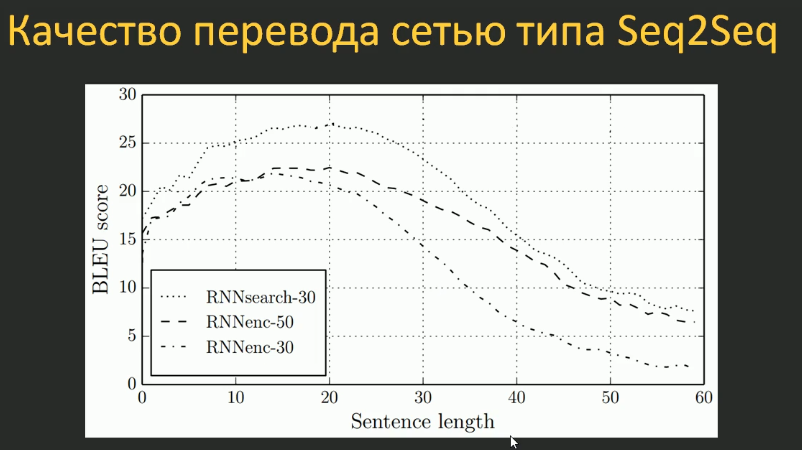

Учесть все слова из енкодера, причем учитывать, какое из них важнее на каждом этапе декодера, позволяет механизм внимания Attention.

Предсказание происходит следующим образом. из енкодера формируется (последний) вектор скрытого состояния h5. Он же является первым для декодера, то есть просто копируется.

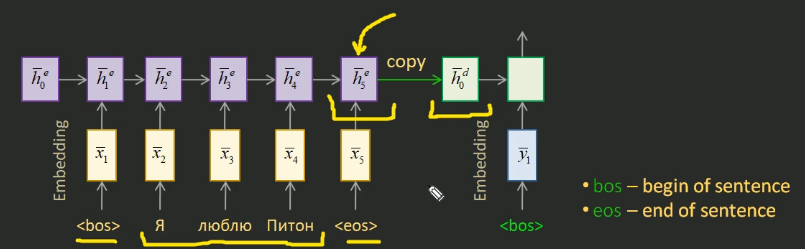

Также в декодер нужно подать какой-то токен/символ. Применительно к тексту перевод обычноначинают с символа bos - beginning of sentence. На основе этой информаци мы могли бы сформирвоать вектор скрытого состояния h1_d. Но в этот раз мы будем учитывать также и все вектора скрытого состояния енкодера

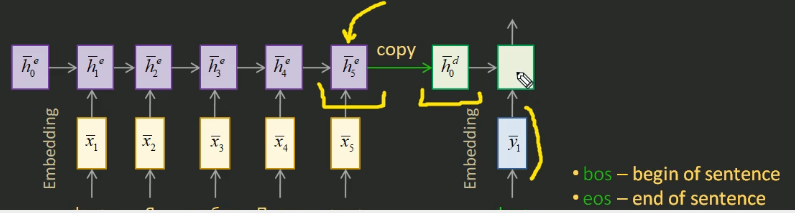
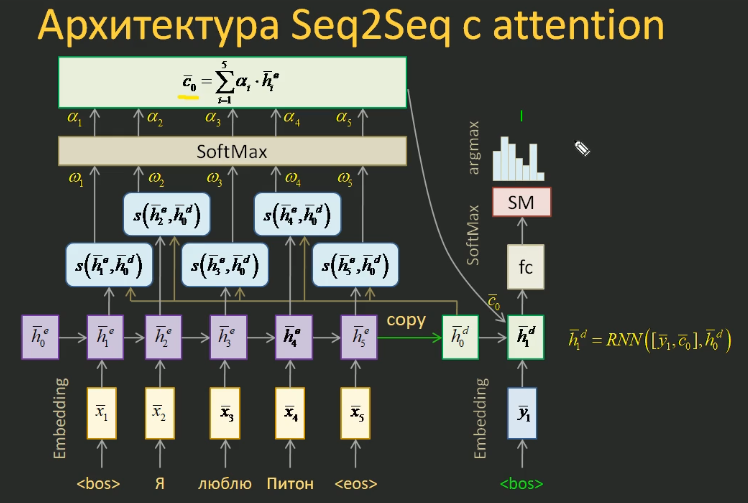

На данном этапе у нас есть вектор скрыого состояния предыдущего шага h0_d и набор векторов скрытого состояния енкодера h_e. Введем какую-нибудь функцию s, которая определет, насколько каждый вектор из h_e важен для формирования вектора в цепочке h_d. Пусть это будет скалярное произведение, а оего можно интерпетировать как меру близости между векторами. Для близких векторов значение больше, для далеких низкое. В общем на данном этапе все вектора из h_e сравниваются с h0_d

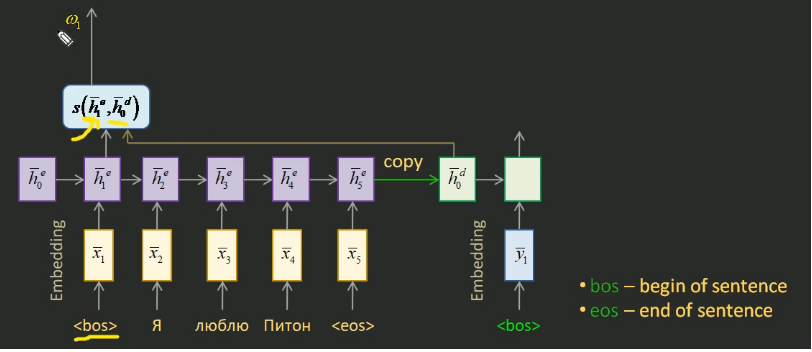

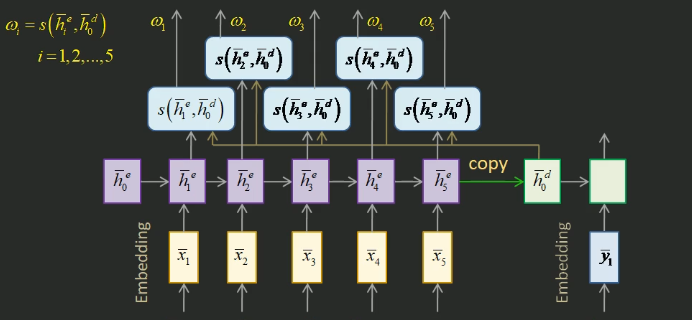

Получили коэффициенты w1...w5. Они показывают важность каждого токена для прогноза слова в декодере. Но у них хрен пойми какой масштаб, поэтму их стоит обернуть в софтмакс. Так мы получаем коэффициенты a1...a5. И при помощи них мы обобщаем все векторы скрытого состояния в единиый вззвешенный вектор скрытого состояния c0. Он содержит информацию обо всех скрытых векторах енкодера

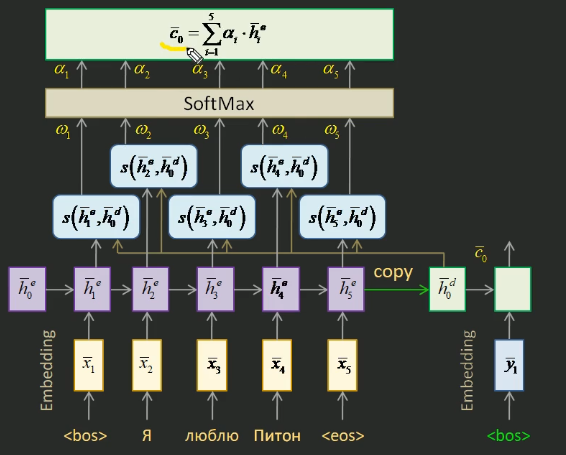

Этот вектор конкатенируется с входым (переводимым) токеном, а точнее его эмбеддингом и вместе с скрытым вектором предыдущего шага подается в рекуррентный слой. Далее как и раньше это отправляется в полносвязный слой и софтмакс, при помощи которого и выбирается предсказанное слово

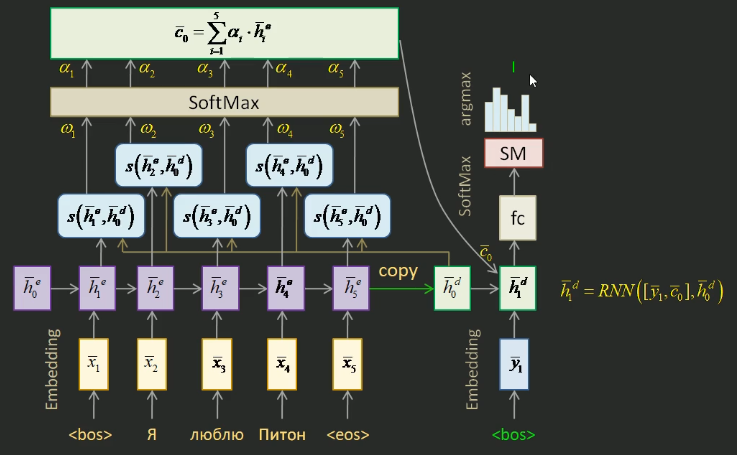
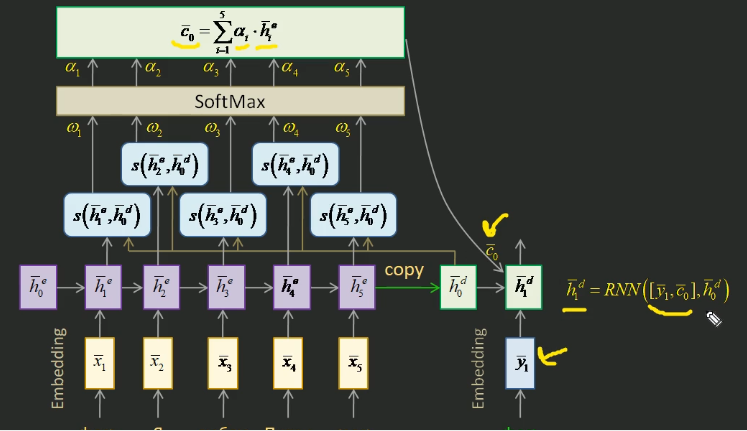
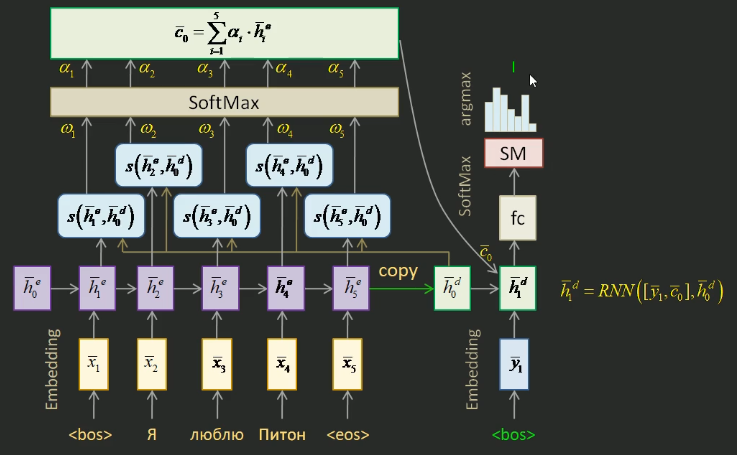

Отдельный вопрос, почему скалярное произведение помогает определить наиболее важное слово для перевода. Дело в том, что это свойство модель приобретает в процессе перевода. ее веса подстраиваются таким образом, чтобы как раз скалярное произведение помогало выбирать наиболее подходящий вектор

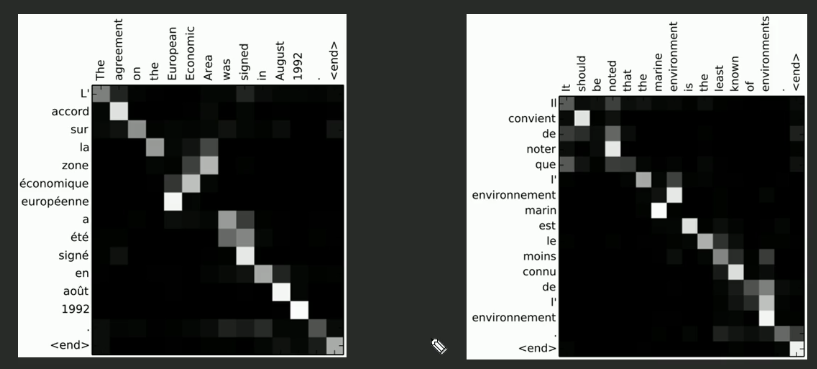

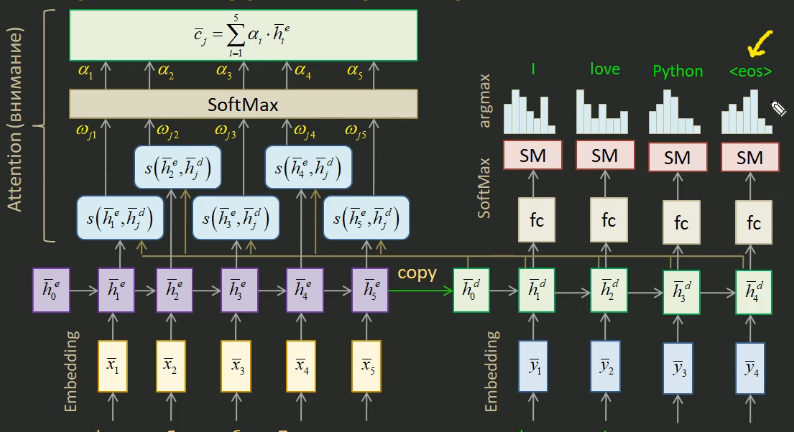

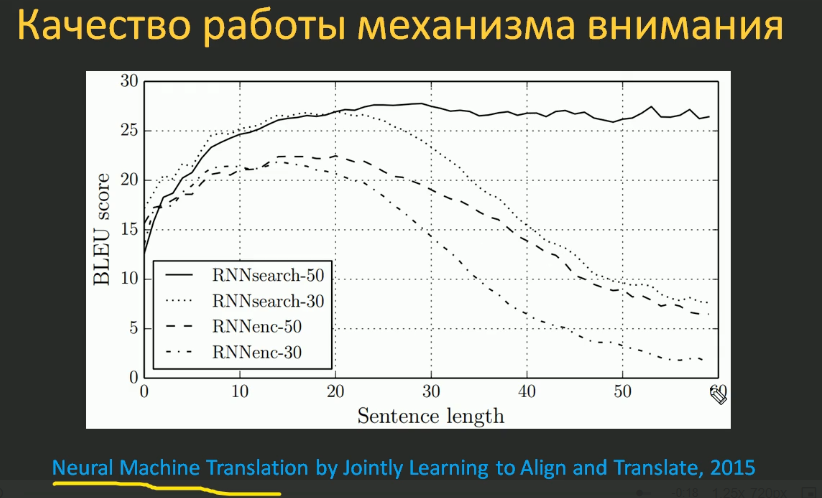